# 01 Exploratory data analysis

A first look at the panel from a pricing desk's point of view: what one row is, what is missing, how spreads behave and what moves them. Training rows describe the target and its drivers. Coverage, grade checks and market trends also use gap and validation snapshots.

Class notebooks followed: the data-loading and EDA sections of `CTrees_titanic` and `RF_risk`.

The test months are not looked at here. Runs top to bottom in about 1 minute; figures go to
`reports/figures/01_*.png`.

In [1]:
# Deck style for every figure: IG is always teal, HY always orange
import matplotlib.pyplot as plt

DECK = {"teal": "#114A6B", "orange": "#FF5F00", "slate": "#3A4550", "grey": "#8A949C", "pale": "#DCE6EC"}
plt.rcParams.update({
    "font.family": "Arial", "font.size": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": DECK["grey"], "axes.labelcolor": DECK["slate"], "axes.titleweight": "bold",
    "axes.titlecolor": DECK["teal"],
    "axes.prop_cycle": plt.cycler(color=[DECK["teal"], DECK["orange"], DECK["grey"], DECK["slate"]]),
    "xtick.color": DECK["slate"], "ytick.color": DECK["slate"], "axes.grid": True, "axes.grid.axis": "y",
    "axes.axisbelow": True, "grid.color": DECK["pale"],
    "figure.figsize": (10, 5.6), "figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight",
})

## 1. Load and check

One row is one bond on one month-end snapshot date (a bond-month).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ml2.config import load_config, resolve
from ml2.data import check_panel, load_column_dictionary, load_panel
from ml2.features import categorical_columns, numeric_columns
from ml2.schema import feature_columns

cfg = load_config()
TARGET = cfg["problem"]["target"]
PREFIX = "01"
FIG = resolve("reports/figures")
FIG.mkdir(parents=True, exist_ok=True)
MATURITY_ORDER = ["1-3y", "3-5y", "5-7y", "7-10y", "10-20y", "20y+"]

def save(fig, name):
    """Save a figure to reports/figures/<prefix>_<name>.png."""
    fig.savefig(FIG / f"{PREFIX}_{name}.png", dpi=150, bbox_inches="tight")


check_panel()
df = load_panel()
print(df.shape, f"{len(feature_columns())} features")
pd.crosstab(df["partition"], df["grade_bucket"], margins=True)

(162207, 46) 33 features


grade_bucket,HY,IG,All
partition,,,
gap,1061,13121,14182
train,9929,109527,119456
valid,2149,26420,28569
All,13139,149068,162207


In [3]:
# From here on: train, gap and valid only. Test stays closed until the final notebook.
seen = df[df.partition != "test"]
train = df[df.partition == "train"]
per_snapshot = seen.groupby("snapshot_date").agg(
    partition=("partition", "first"), rows=("cusip_id", "size"),
    bonds=("cusip_id", "nunique"), issuers=("issuer_ticker", "nunique"))
per_snapshot

,partition,rows,bonds,issuers
snapshot_date,,,,
2024-01-31,train,7033,7033,774
2024-02-29,train,7103,7103,778
2024-03-28,train,6700,6700,766
2024-04-30,train,7210,7210,779
2024-05-31,train,6802,6802,765
2024-06-28,train,6803,6803,766
2024-07-31,train,7082,7082,771
2024-08-30,train,6720,6720,765
2024-09-30,train,7271,7271,778


Across the 23 non-test snapshots, coverage ranges from 6,623 to 7,406 bonds and 752 to 779 identified issuers per date. The number of observations is fairly stable, although individual bonds can enter and leave. Of 119,456 training bond-months, 109,527 are investment grade (IG) and 9,929 are high yield (HY). An overall error metric therefore gives much more weight to IG.

## 2. Missing values

Share of missing values per feature. Nothing is filled here: the shared preprocessor imputes inside each model (median plus a missing flag).

,train,valid
naive_dd,0.116,0.111
leverage,0.115,0.111
total_debt,0.098,0.093
log_market_cap,0.046,0.046
ret_252d,0.030,0.028
mom_12_1,0.030,0.028
vol_252d,0.029,0.028
beta_252d,0.029,0.028
vol_60d,0.029,0.028
vol_20d,0.029,0.028


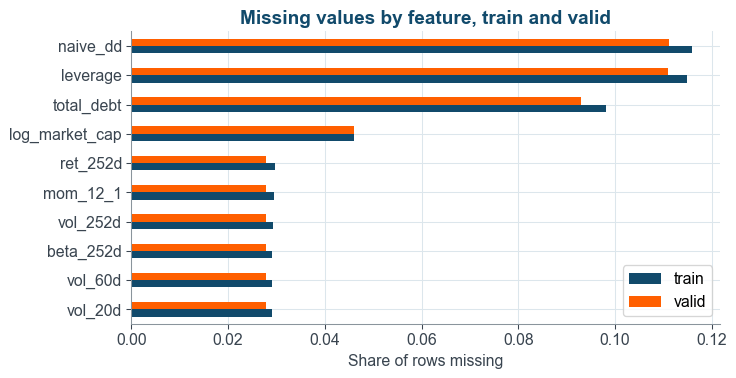

In [4]:
feats = feature_columns()
missing = pd.DataFrame({
    "train": train[feats].isna().mean(),
    "valid": seen.loc[seen.partition == "valid", feats].isna().mean(),
}).sort_values("train", ascending=False)
missing = missing[missing.max(axis=1) > 0]

fig, ax = plt.subplots(figsize=(8, 0.3 * len(missing) + 1))
missing[::-1].plot.barh(ax=ax)
ax.set_xlabel("Share of rows missing")
ax.set_title("Missing values by feature, train and valid")
save(fig, "missing")
missing.round(3)

Distance to default and leverage have the most gaps (11.6% and 11.5% of training rows). Both depend on balance-sheet inputs. The panel also leaves stock data empty when an issuer cannot be matched reliably. Validation has a similar missingness pattern. Imputation takes place within the fitted preprocessing pipeline.

## 3. The target

`spread_bps`: bond yield minus the Treasury yield of the same maturity, in basis points. Train rows only.

                 count   mean    std   min  ...    75%    95%     99%     max
grade_bucket                                ...                              
HY              9929.0  256.1  260.5 -73.4  ...  268.4  602.3  1624.6  2993.0
IG            109527.0   87.7   41.0 -91.5  ...  110.4  156.0   202.2  1304.5

[2 rows x 11 columns]
skewness: {'HY': 5.43, 'IG': 1.63}


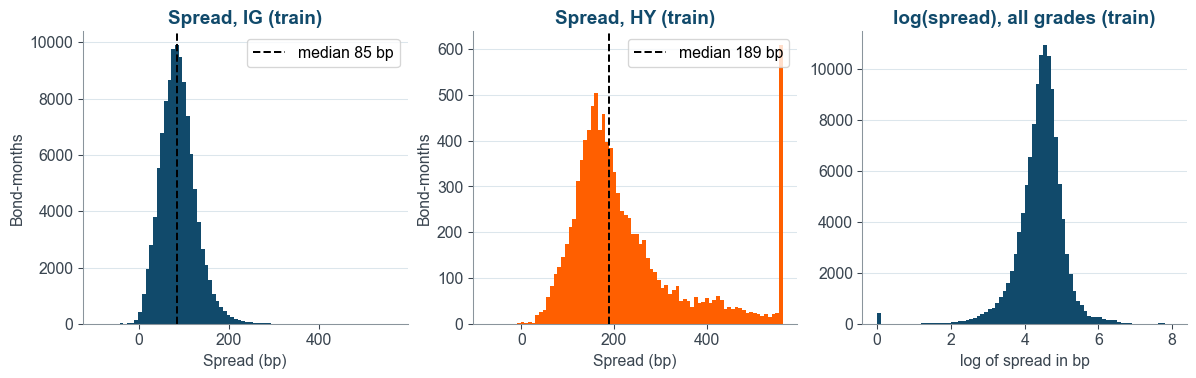

In [5]:
print(train.groupby("grade_bucket")[TARGET].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(1))
print("skewness:", train.groupby("grade_bucket")[TARGET].skew().round(2).to_dict())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
cap = train[TARGET].quantile(0.995)
for ax, g in zip(axes[:2], ["IG", "HY"]):
    s = train.loc[train.grade_bucket == g, TARGET]
    ax.hist(s.clip(upper=cap), bins=80, color=DECK["teal"] if g == "IG" else DECK["orange"])
    ax.axvline(s.median(), color="black", ls="--", label=f"median {s.median():.0f} bp")
    ax.set_title(f"Spread, {g} (train)"); ax.set_xlabel("Spread (bp)"); ax.set_ylabel("Bond-months"); ax.legend()
axes[2].hist(np.log(train[TARGET].clip(lower=1)), bins=80)
axes[2].set_title("log(spread), all grades (train)"); axes[2].set_xlabel("log of spread in bp")
save(fig, "target")

The training median is 85 bp in IG and 189 bp in HY. At the 99th percentile the figures are 202 and 1,625 bp. The longer HY tail makes a shifted log target worth testing. Some spreads are negative, so an ordinary log would lose observations. Compare predictions on the original basis-point scale, where the desk measures error.

## 4. What drives spreads

grade_bucket,IG,HY
maturity_bucket,,
1-3y,52.0,156.0
3-5y,69.0,189.0
5-7y,81.0,188.0
7-10y,95.0,196.0
10-20y,103.0,242.0
20y+,104.0,202.0


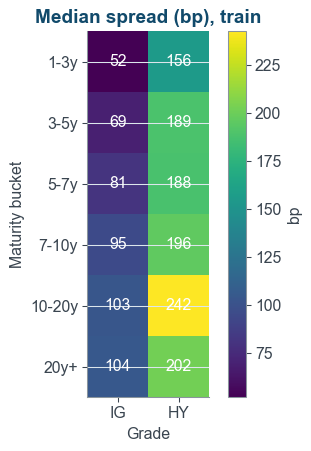

In [6]:
heat = train.pivot_table(index="maturity_bucket", columns="grade_bucket", values=TARGET, aggfunc="median")
heat = heat.loc[MATURITY_ORDER, ["IG", "HY"]]

fig, ax = plt.subplots(figsize=(5, 5))
im = ax.imshow(heat.values, cmap="viridis")
ax.set_xticks(range(heat.shape[1]), heat.columns); ax.set_yticks(range(heat.shape[0]), heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f"{heat.values[i, j]:.0f}", ha="center", va="center", color="white")
ax.set_xlabel("Grade"); ax.set_ylabel("Maturity bucket")
ax.set_title("Median spread (bp), train")
fig.colorbar(im, ax=ax, label="bp")
save(fig, "heatmap_maturity_grade")
heat.round(0)

grade_bucket,IG,HY
sector,,
Consumer Staples,67.0,177.0
Information Technology,73.0,163.0
Industrials,76.0,167.0
Consumer Discretionary,77.0,169.0
Health Care,78.0,155.0
Financials,87.0,263.0
Unknown,89.0,244.0
Communication Services,91.0,230.0
Real Estate,93.0,280.0


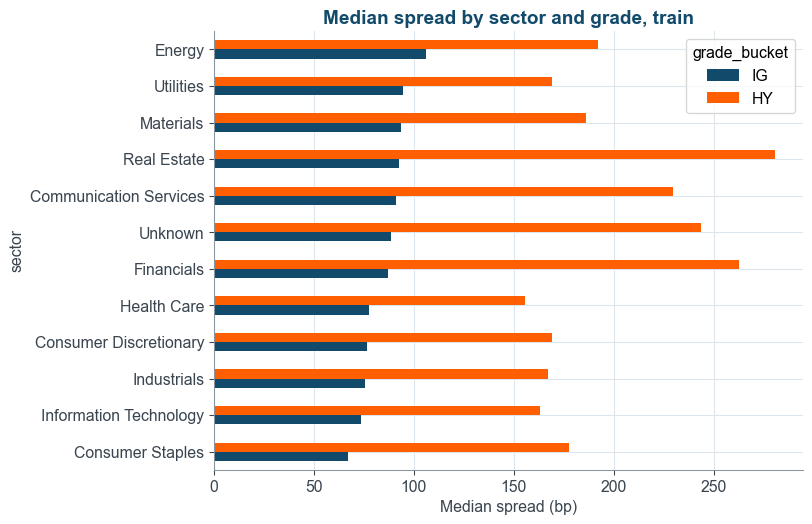

In [7]:
by_sector = train.groupby(["sector", "grade_bucket"])[TARGET].median().unstack()[["IG", "HY"]]
by_sector = by_sector.sort_values("IG")
fig, ax = plt.subplots(figsize=(8, 6))
by_sector.plot.barh(ax=ax)
ax.set_xlabel("Median spread (bp)"); ax.set_title("Median spread by sector and grade, train")
save(fig, "sector")
by_sector.round(0)

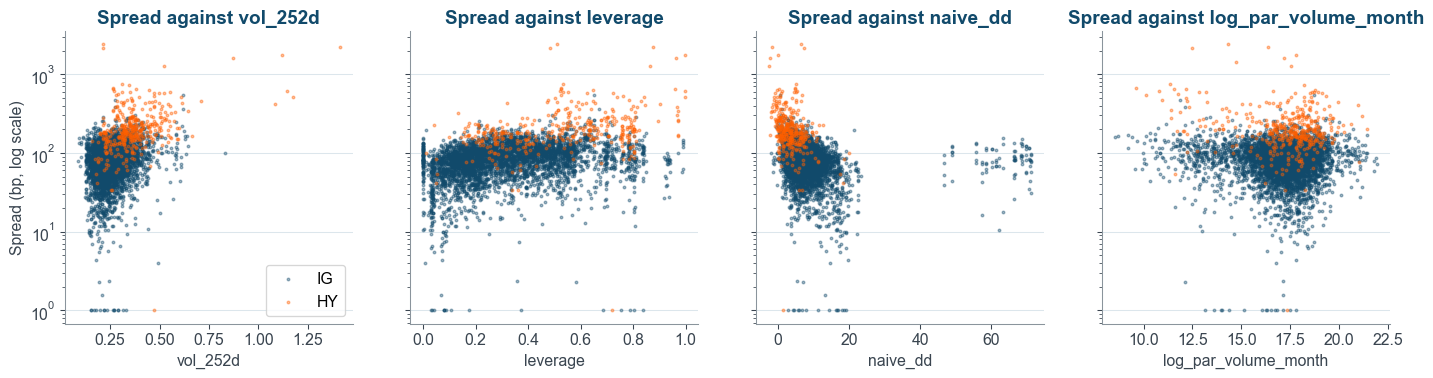

In [8]:
pts = train.sample(5000, random_state=42)
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, col in zip(axes, ["vol_252d", "leverage", "naive_dd", "log_par_volume_month"]):
    for g, colour in [("IG", DECK["teal"]), ("HY", DECK["orange"])]:
        p = pts[pts.grade_bucket == g]
        ax.scatter(p[col], p[TARGET].clip(lower=1), s=4, alpha=0.4, color=colour, label=g)
    ax.set_yscale("log"); ax.set_xlabel(col); ax.set_title(f"Spread against {col}")
axes[0].set_ylabel("Spread (bp, log scale)"); axes[0].legend()
save(fig, "scatter_drivers")

IG median spreads rise from 52 bp at 1–3 years to 104 bp beyond 20 years. HY medians exceed IG in every bucket but peak at 242 bp in the 10–20 year bucket. Sector rankings depend on grade: Energy has the widest IG median (106 bp), while Real Estate has the widest HY median (280 bp). In training, spreads tend to increase with leverage and volatility and decrease with distance to default. Monthly trading volume on its own shows little association.

## 5. The market over time

Median spread per snapshot next to the high-yield index spread (`hy_oas_bps`). Train, gap and valid only.

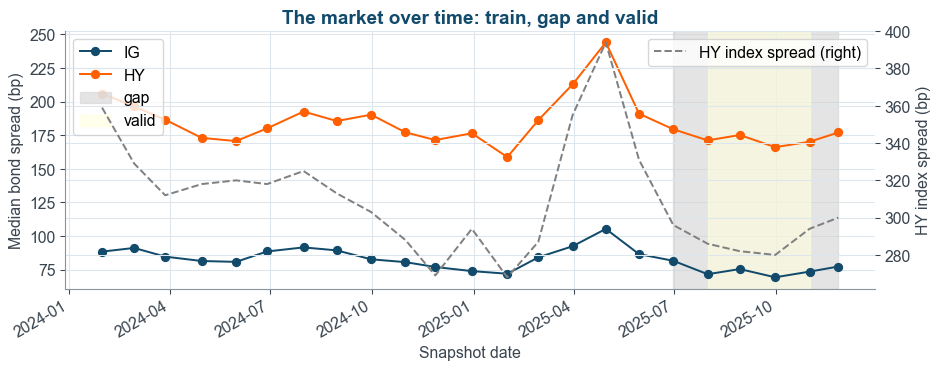

In [9]:
over_time = seen.groupby(["snapshot_date", "grade_bucket"])[TARGET].median().unstack()[["IG", "HY"]]
oas = seen.groupby("snapshot_date")["hy_oas_bps"].median()

fig, ax = plt.subplots(figsize=(11, 4))
over_time.plot(ax=ax, marker="o")
ax2 = ax.twinx()
oas.plot(ax=ax2, color="grey", ls="--", label="HY index spread (right)")
for part, colour in [("gap", "lightgrey"), ("valid", "lightyellow")]:
    d = per_snapshot.index[per_snapshot.partition == part]
    if len(d):
        ax.axvspan(d.min(), d.max(), color=colour, alpha=0.6, label=part)
ax.set_ylabel("Median bond spread (bp)"); ax2.set_ylabel("HY index spread (bp)")
ax.set_xlabel("Snapshot date"); ax.set_title("The market over time: train, gap and valid")
ax.legend(loc="upper left"); ax2.legend(loc="upper right")
save(fig, "market_over_time")

The median spread fell between training and validation, from 85 to 72 bp for IG and from 189 to 171 bp for HY. A price based only on older peers can miss that change in market level. Notebook 02 checks whether using same-date peers reduces pricing error in each grade.

## 6. Correlations

,,correlation
ret_252d,mom_12_1,0.95
slope_2s10s_bps,sofr_pct,-0.92
hy_oas_bps,bbb_oas_bps,0.92
vol_60d,vol_252d,0.84
ust_2y_pct,slope_2s10s_bps,-0.82


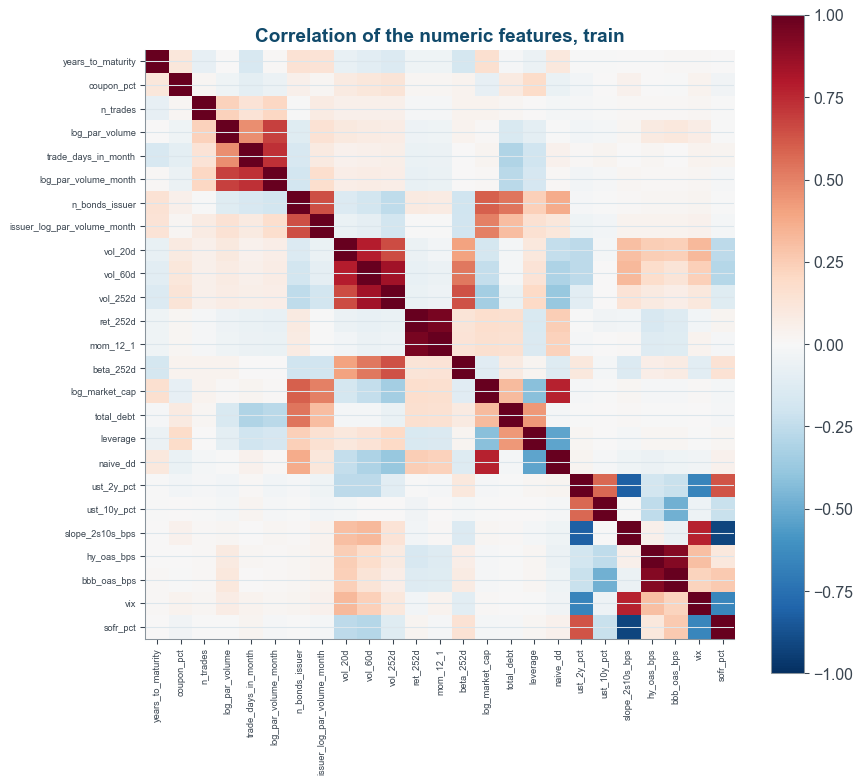

In [10]:
num = [c for c in numeric_columns() if train[c].nunique() > 2]
corr = train[num].corr()

fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(num)), num, rotation=90, fontsize=7); ax.set_yticks(range(len(num)), num, fontsize=7)
ax.set_title("Correlation of the numeric features, train")
fig.colorbar(im, ax=ax)
save(fig, "correlations")

upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
high = upper[upper.abs() > 0.8].sort_values(key=abs, ascending=False)
high.round(2).rename("correlation").to_frame()

The strongest overlap is between one-year stock return and momentum (0.95). Other pairs above 0.8 in absolute value are the yield-curve slope and SOFR (−0.92), HY and BBB index spreads (0.92), 60- and 252-day volatility (0.84), and the two-year Treasury yield and curve slope (−0.82). These overlaps help explain why the independence assumption in Naive Bayes deserves a sensitivity check.

## 7. Data quality

Report problems; do not silently drop rows.

In [11]:
# Spot-check 10 companies: does the issuer name match the ticker's company?
names = train.drop_duplicates("issuer_ticker")[["issuer_ticker", "issuer_name", "sector", "grade_bucket"]]
names.sample(10, random_state=1)

In [12]:
# The 10 widest and 10 narrowest spreads per grade
cols = ["snapshot_date", "issuer_name", "years_to_maturity", "coupon_pct", "price", TARGET]
for g in ["IG", "HY"]:
    t = train[train.grade_bucket == g]
    print(f"--- {g}: widest"); print(t.nlargest(10, TARGET)[cols].to_string(index=False))
    print(f"--- {g}: narrowest"); print(t.nsmallest(10, TARGET)[cols].to_string(index=False))

In [13]:
# Is each company graded consistently? Bonds graded differently from most of their company's bonds
first = seen.drop_duplicates("cusip_id")
issuer_grade = first.groupby("issuer_ticker")["grade_bucket"].agg(lambda s: s.value_counts().index[0])
graded = seen.assign(issuer_grade=seen["issuer_ticker"].map(issuer_grade))
odd = graded[graded["issuer_grade"].notna() & graded["grade_bucket"].ne(graded["issuer_grade"])]
print(f"{len(odd):,} bond-months differ from the issuer majority among rows with a known issuer grade")
odd.groupby(["issuer_grade", "grade_bucket"])[TARGET].agg(["size", "median"]).round(0)

1,409 bond-months differ from the issuer majority among rows with a known issuer grade


,,size,median
issuer_grade,grade_bucket,,
HY,IG,466,157.0
IG,HY,943,132.0


In [14]:
# Sector coverage after harmonisation to GICS names
train["sector"].fillna("Unknown").value_counts()

,count
sector,
Financials,21961
Utilities,16305
Industrials,12498
Health Care,10314
Consumer Discretionary,10155
Energy,8450
Consumer Staples,7821
Information Technology,7812
Real Estate,6847


Training spreads include negatives in both grades and reach nearly 3,000 bp in HY. Price and maturity can help flag records for review, but extreme values alone do not establish distress or a data error. Among non-test observations with a known issuer grade, 466 IG bond-months belong to majority-HY issuers (median 157 bp), and 943 HY bond-months belong to majority-IG issuers (132 bp). Keep the documented bond grade for evaluation. The harmonised sector labels still include 6,599 Unknown training observations.

## Technical annex

The panel is a series of month-end cross-sections. Each observation is one bond on one date. A typical month covers about 7,000 bonds, but a stable count does not imply an unchanged set of bonds. We use the panel's grade bucket throughout: TRACE flag I denotes investment grade and H denotes high yield. When the bond's master record postdates all its trades, the panel uses the majority grade of the issuer's other bonds. The grade flag is based on the latest master record, which limits its interpretation as a historical rating.

Grade matters for both price and evaluation. HY represents only 8.3% of training observations, yet its 99th-percentile spread is roughly eight times the IG value. An aggregate error can look acceptable even when the model prices riskier bonds poorly. We therefore report errors for both strata. The market level also changed across the split: both grade medians were lower in validation. Comparing a frozen pricing matrix with a same-date matrix quantifies how much updating the reference prices helps.

### Report findings

- The median training spread was 85 bp for IG and 189 bp for HY.
- Wider HY spreads and a small HY sample make grade-specific error reporting essential.
- Median spreads fell by about 13 bp for IG and 18 bp for HY between training and validation.
- Leverage and distance to default have the largest coverage gaps. Both are missing for roughly one in nine training observations.